### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_UESWXDCOJRNO


### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from nptdms import TdmsFile
import h5py
import cv2
import glob, os
from roifile import roiread

In [4]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.lsn import get_ett_vectorized, plot_lsn_response, analyze_rf, plot_rf, fit_vector_field, plot_retinotopy, plot_vector_field

In [5]:
from matplotlib import font_manager
import matplotlib as mpl

font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### Load data

In [6]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field"

In [7]:
database = [
    {
        "name": "20250520_rec3",
        "table": "/bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field/20250520_rec3/plots/result.hdf5",
        "template": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec3/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif",
        "roi": "/bucket/ReiterU/OLdev/experiments/20250520_squid_cal520/2P/rec3/ROI_transformed_corrected.zip"
    },
    {
        "name": "20250522_rec2",
        "table": "/bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field/20250522_rec2/plots/result.hdf5",
        "template": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif",
        "roi": "/bucket/ReiterU/OLdev/experiments/20250522_squid_cal520/2P/rec2/ROI_van_renamed.zip"
    },
]

R, E = [], []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["table"], mode='r') as store:
        r = store["R"]
        # e = store["E"]
    r["recording"] = k
    # e["recording"] = k
    # e = e.reset_index().set_index(["recording", "neuron", "y", "x", "trial", "time"])
    R.append(r)
    # E.append(e)
R = pd.concat(R)
R.reset_index(drop=True, inplace=True)

contours = []
for (k, d) in enumerate(database):
    rois = roiread(d["roi"])
    rois = sorted(rois, key=lambda x: x.name)  # sort the list
    conts = [r.subpixel_coordinates.astype("int") for r in rois]
    contours.append(conts)

templates = []
for (k, d) in enumerate(database):
    templates.append(cv2.imread(d["template"], -1))

# E = pd.concat(E)

In [8]:
display(R)

,neuron,azimuth,elevation,size,x,y,test,recording
0,0,0.000000,0.000000,0.0,66.392548,51.111679,False,0
1,1,45.666667,0.333333,12.0,42.454231,67.364670,False,0
2,2,0.000000,0.000000,0.0,53.773361,70.063293,False,0
3,3,0.000000,0.000000,0.0,50.320396,82.175369,False,0
4,4,0.000000,0.000000,0.0,22.518013,73.431984,False,0
...,...,...,...,...,...,...,...,...
402,233,-11.375000,3.250000,64.0,60.917030,211.216263,True,1
403,234,-10.000000,3.375000,64.0,47.822670,216.787994,True,1
404,235,-11.400000,2.466667,60.0,55.439091,238.857269,True,1
405,236,3.000000,19.000000,12.0,64.787270,235.087265,False,1


In [9]:
print("Number of good cells:", R[R["test"]].shape[0])

Number of good cells: 297


0 azimuth


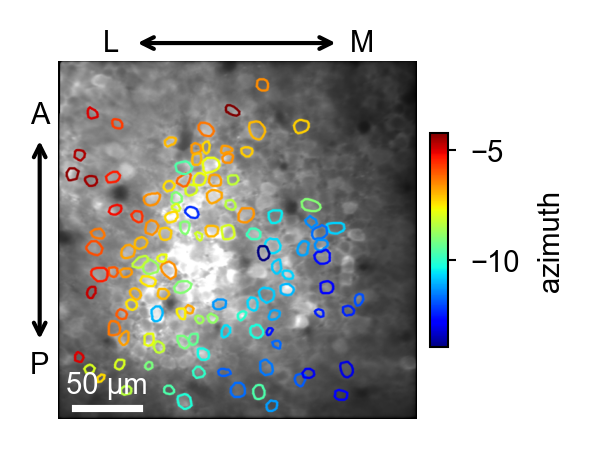

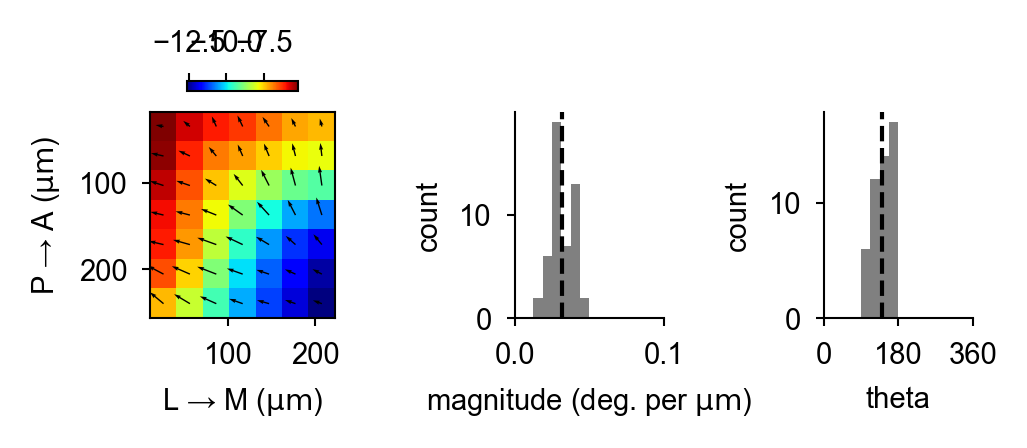

0 elevation


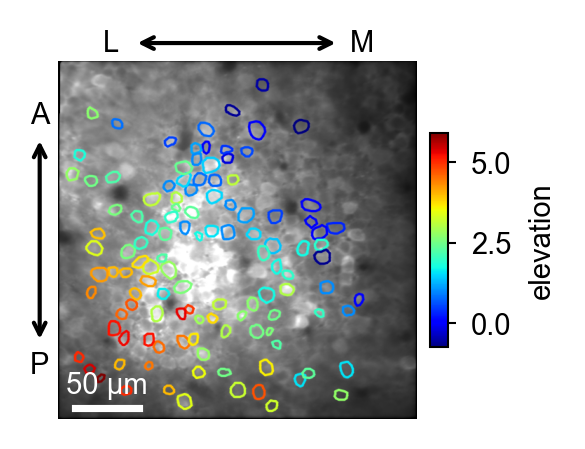

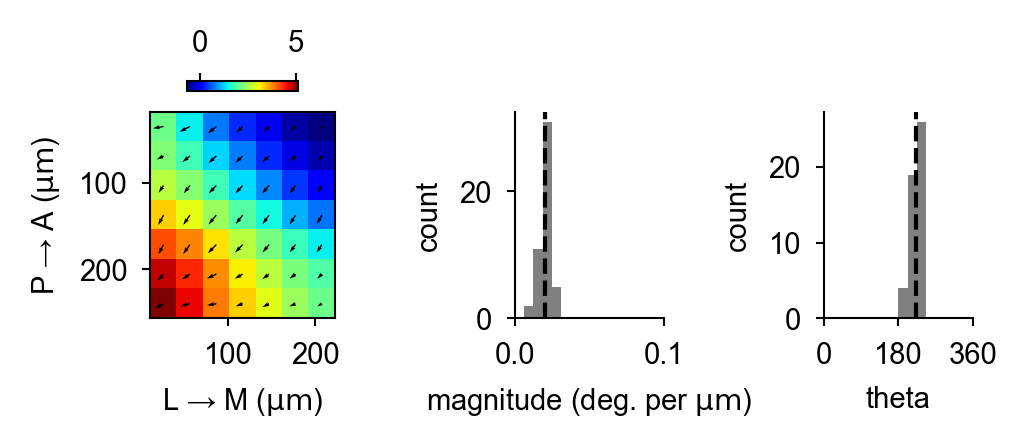

1 azimuth


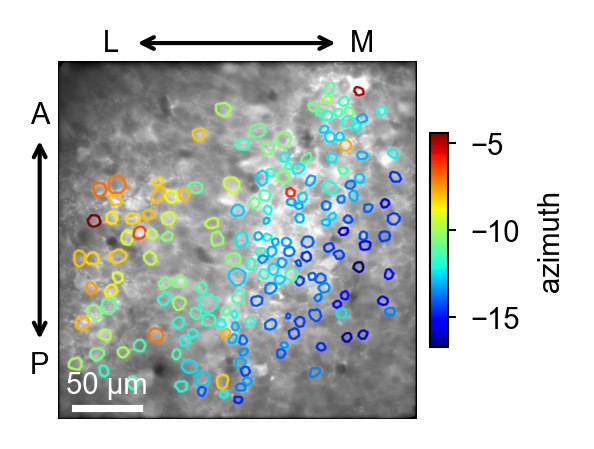

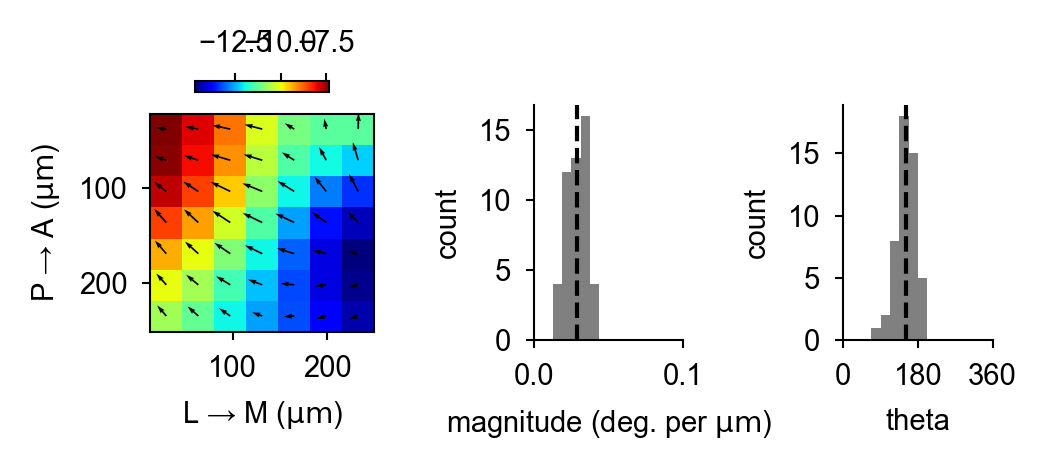

1 elevation


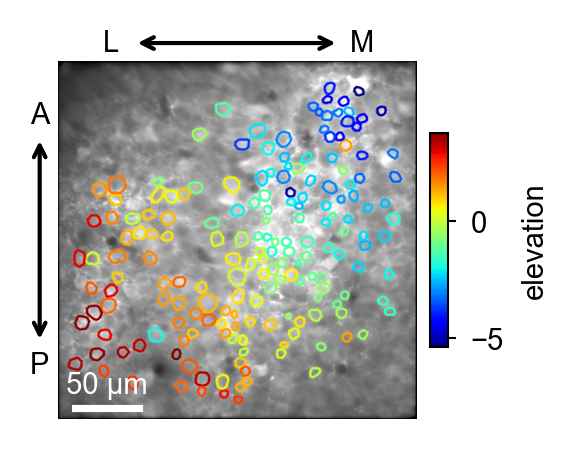

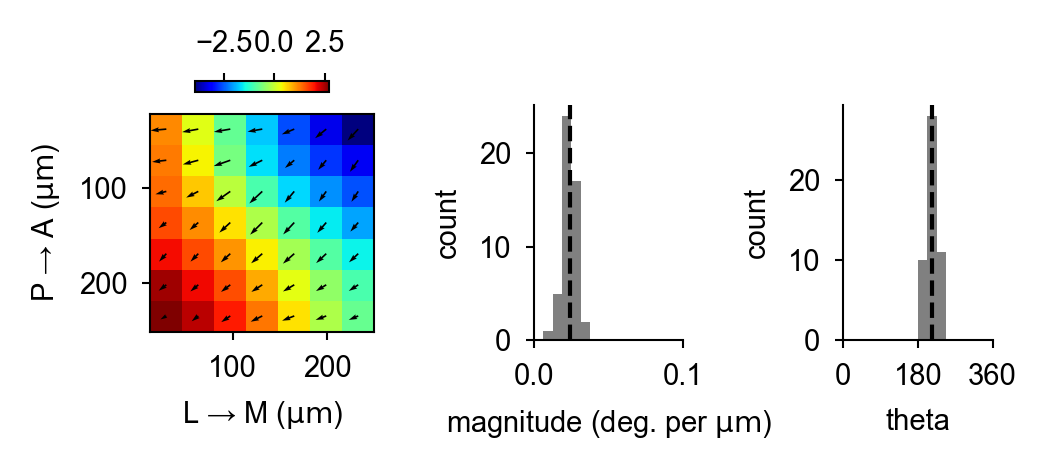

In [10]:
data = []

for rec in range(2):
    for direction in ["azimuth", "elevation"]:
        print(rec, direction)
        R_filtered = R[(R["recording"] == rec) & R["test"]]
        contours_filtered = [c for (i, c) in enumerate(contours[rec]) if i in R_filtered["neuron"].to_list()]
        plot_retinotopy(R_filtered, direction, templates[rec], contours_filtered,
                        show_cell_id=False,
                        figsize=(1.55,1.55),
                        figsavename=os.path.join(tmpdir, f"rec{rec}_retinotopy_{direction}.pdf"))
        vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(R_filtered, direction, n_bins=7)
        theta, grad_amp = plot_vector_field(R_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y,
                                            figsize=(3.5,1.55), figsavename=os.path.join(tmpdir, f"rec{rec}_retinotopy_vfield_{direction}.pdf"))
    
        data.append({
            "rec": rec,
            "direction": direction,
            "grad_x": grad_x,
            "grad_y": grad_y,
            "grad_amp": grad_amp,
            "theta": theta
        })

### RF size distribution

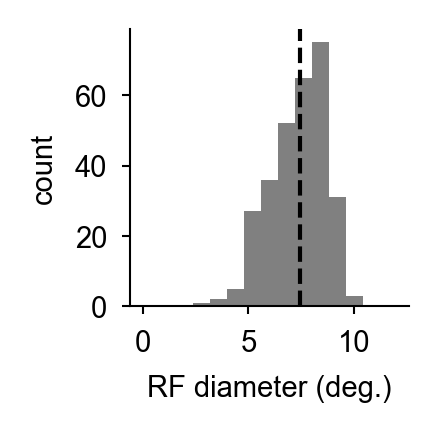

In [12]:
fig = plt.figure(figsize=(1.2,1.2), dpi=300)
gs = fig.add_gridspec(1,1)
ax = fig.add_subplot(gs[0, 0])

rf_sizes = R[R["test"]]["size"].to_numpy()
rf_diameter = 2 * np.sqrt(rf_sizes / np.pi)
count, bin_edges = np.histogram(rf_diameter, range=[0, 12], bins=15, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, color="gray")
ax.axvline(np.mean(rf_diameter), lw=1, color="k", ls="--")
ax.set_xlabel("RF diameter (deg.)")
ax.set_ylabel("count")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
ax.set_ylim(bottom=0)
plt.savefig(os.path.join(tmpdir, "rf_size_distribution.pdf"), bbox_inches='tight')
plt.show()

In [13]:
rf_sizes

array([20., 36., 48., 44., 60., 36., 40., 20., 60., 40., 40., 48., 20.,
       56., 12., 68., 36., 44., 28., 44., 40., 52., 32., 48., 20., 28.,
       52., 48., 52., 72., 44., 48., 40., 36., 20., 24., 36., 68., 32.,
       36., 48., 44., 44., 44., 40., 24., 16., 64., 48., 24., 52., 32.,
       20., 52., 44., 60., 28., 60., 44., 24., 40., 16., 28., 32., 56.,
       32., 28., 52., 40., 44., 60., 32., 48., 20., 48., 52., 60., 60.,
       36., 40., 56., 52., 56., 40., 40., 52., 36., 28., 84., 80., 48.,
       40., 48., 32., 56., 48., 16., 20., 36., 60., 32., 48., 60., 16.,
       44., 36., 52., 52., 40., 48., 40., 16., 44., 36., 52., 52., 40.,
       60., 56., 40., 56., 60., 32., 36., 36., 48., 48., 56., 56., 48.,
       52., 40., 56., 36., 28., 44., 52., 60., 72., 64., 56., 44., 40.,
       28., 48., 32., 36., 24., 32., 20., 44., 48., 72., 48., 52., 20.,
       40., 64., 52., 64., 20., 52., 64., 64., 48., 60., 24., 48., 48.,
       52., 32., 72., 64., 56., 32., 64., 48., 52., 44., 52., 40

### Plot gradient direction and amplitude

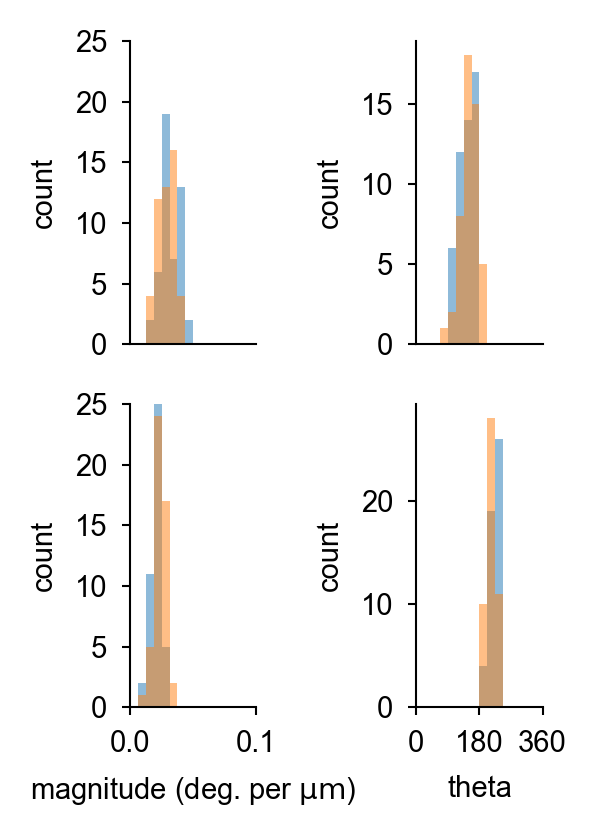

In [14]:
fig = plt.figure(figsize=(2,2.8), dpi=300)
gs = fig.add_gridspec(2, 2)

ax = fig.add_subplot(gs[0, 0])
for i in range(3):
    grad_amp = [e["grad_amp"] for e in data if (e["rec"] == i) and (e["direction"] == "azimuth")]
    count, bin_edges = np.histogram(grad_amp, range=[0, 0.1], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, label=f"rec{i}")
ax.set_ylabel("count")
ax.set_xlim([0,0.1])
ax.set_ylim([0,25])
ax.set_xticks([])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[1, 0])
for i in range(3):
    grad_amp = [e["grad_amp"] for e in data if (e["rec"] == i) and (e["direction"] == "elevation")]
    count, bin_edges = np.histogram(grad_amp, range=[0, 0.1], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, label=f"rec{i}")
ax.set_xlabel("magnitude (deg. per $\mathrm{\mu m}$)")
ax.set_ylabel("count")
ax.set_xlim([0, 0.1])
ax.set_ylim([0,25])
# ax.legend()
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[0,1])
for i in range(3):
    theta = [e["theta"] for e in data if (e["rec"] == i) and (e["direction"] == "azimuth")]
    count, bin_edges = np.histogram(theta, range=[0,360], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, label=f"rec{i}")
ax.set_ylabel("count")
ax.set_xlim([0, 360])
ax.set_xticks([0, 180, 360])
ax.set_xticks([])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[1, 1])
for i in range(3):
    theta = [e["theta"] for e in data if (e["rec"] == i) and (e["direction"] == "elevation")]
    count, bin_edges = np.histogram(theta, range=[0, 360], bins=16, density=False)
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, label=f"rec{i}")
ax.set_xlabel("theta")
ax.set_ylabel("count")
ax.set_xlim([0, 360])
ax.set_xticks([0, 180, 360])
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "rf_gradient_summary.pdf"), bbox_inches='tight')
plt.show()

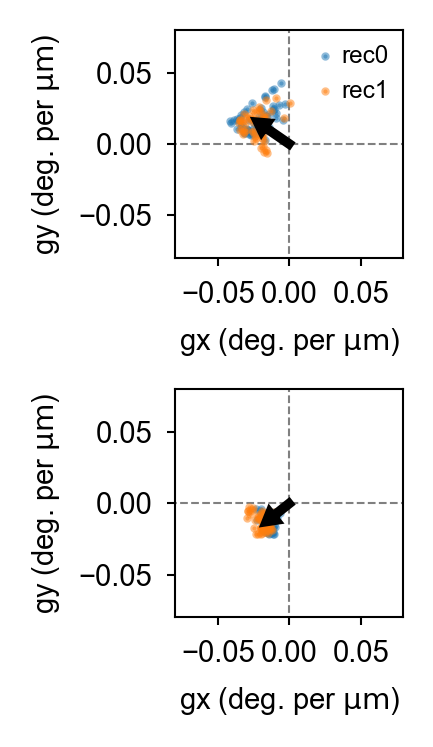

In [16]:
fig = plt.figure(figsize=(2,2.5), dpi=300)
gs = fig.add_gridspec(2, 1)

for i in range(2):
    direction = "azimuth" if i == 0 else "elevation"
    ax = fig.add_subplot(gs[i,0])
    tmp1, tmp2 = [], []
    for j in range(2):
        gx = [e["grad_x"] for e in data if (e["rec"] == j) and (e["direction"] == direction)]
        gy = [e["grad_y"] for e in data if (e["rec"] == j) and (e["direction"] == direction)]
        gx = gx[0].flatten()
        gy = (-1) * gy[0].flatten()
        tmp1.append(gx)
        tmp2.append(gy)
        ax.scatter(gx, gy, s=1, zorder=10, alpha=0.5, label=f"rec{j}")
    gx_mean = np.mean(np.concatenate(tmp1))
    gy_mean = np.mean(np.concatenate(tmp2))
    ax.arrow(0, 0, gx_mean, gy_mean, zorder=11, lw=2, length_includes_head=True, head_width=0.008, head_length=0.007, color="k")
    ax.hlines(0, -0.1, 0.1, lw=0.5, color="gray", ls="--")
    ax.vlines(0, -0.1,0.1, lw=0.5, color="gray", ls="--")
    ax.set_xlim(-0.08, 0.08)
    ax.set_ylim(-0.08, 0.08)
    ax.set_aspect("equal")
    ax.set_xlabel("gx (deg. per $\mathrm{\mu m}$)")
    ax.set_ylabel("gy (deg. per $\mathrm{\mu m}$)")
    if i == 0:
        ax.legend(loc='upper right', fontsize="small", frameon=False, handlelength=1.0, handletextpad=0.2, borderaxespad=0.2)

plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "rf_gradient_scatter.pdf"), bbox_inches='tight')
plt.show()

### Response of an example neuron

In [17]:
# with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20241022_rec8/plots/result.hdf5", mode='r') as store:
#     E = store["E"]

In [18]:
# nid = 10
# plot_lsn_response(E, nid, 0, 1000, vmin=-0.1, vmax=0.5, cmap_name="viridis")
# rf =  analyze_rf(E, nid, 0, 1000, 2.0, peak_thresh=3.0, blob_thresh=2.5, sigma=0)
# plot_rf(E, nid, rf, 0, 1000, vmin=-0.1, vmax=0.5, figsize=(3.7, 1.5), figsavename=os.path.join(tmpdir, f"20241022_rec8_{nid}.pdf"))

### Copy data to bucket

In [19]:
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field
cp -r /flash/ReiterU/tmp/tomo_ISUENCLUCCZH/* /bucket/ReiterU/OLdev/analysis/20250608_IGL_receptive_field
